#### Evaluating the model

In [37]:
import numpy as np

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
import pandas as pd

In [39]:
dataset_path = '/content/Heart Disease.csv'

In [40]:
df= pd.read_csv(dataset_path)
df.tail(10)

,gender,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,Heart Disease (in next 10 years)
4230,Female,56,1.0,1,3.0,0.0,0,1,0,268.0,170.0,102.0,22.89,57.0,NaN,0
4231,Male,58,3.0,0,0.0,0.0,0,1,0,187.0,141.0,81.0,24.96,80.0,81.0,0
4232,Male,68,1.0,0,0.0,0.0,0,1,0,176.0,168.0,97.0,23.14,60.0,79.0,1
4233,Male,50,1.0,1,1.0,0.0,0,1,0,313.0,179.0,92.0,25.97,66.0,86.0,1
4234,Male,51,3.0,1,43.0,0.0,0,0,0,207.0,126.5,80.0,19.71,65.0,68.0,0
4235,Female,48,2.0,1,20.0,NaN,0,0,0,248.0,131.0,72.0,22.00,84.0,86.0,0
4236,Female,44,1.0,1,15.0,0.0,0,0,0,210.0,126.5,87.0,19.16,86.0,NaN,0
4237,Female,52,2.0,0,0.0,0.0,0,0,0,269.0,133.5,83.0,21.47,80.0,107.0,0
4238,Male,40,3.0,0,0.0,0.0,0,1,0,185.0,141.0,98.0,25.60,67.0,72.0,0
4239,Female,39,3.0,1,30.0,0.0,0,0,0,196.0,133.0,86.0,20.91,85.0,80.0,0


## What is ROC and AUC?

**ROC Curve:** It’s a plot of True Positive Rate (TPR) vs False Positive Rate (FPR) at various threshold settings.

TPR (Recall) = TP / (TP + FN)

FPR = FP / (FP + TN)

**AUC (Area Under the Curve):** It tells how much the model is capable of distinguishing between classes.

AUC = 1: Perfect classifier

AUC = 0.5: No discrimination (random guessing)

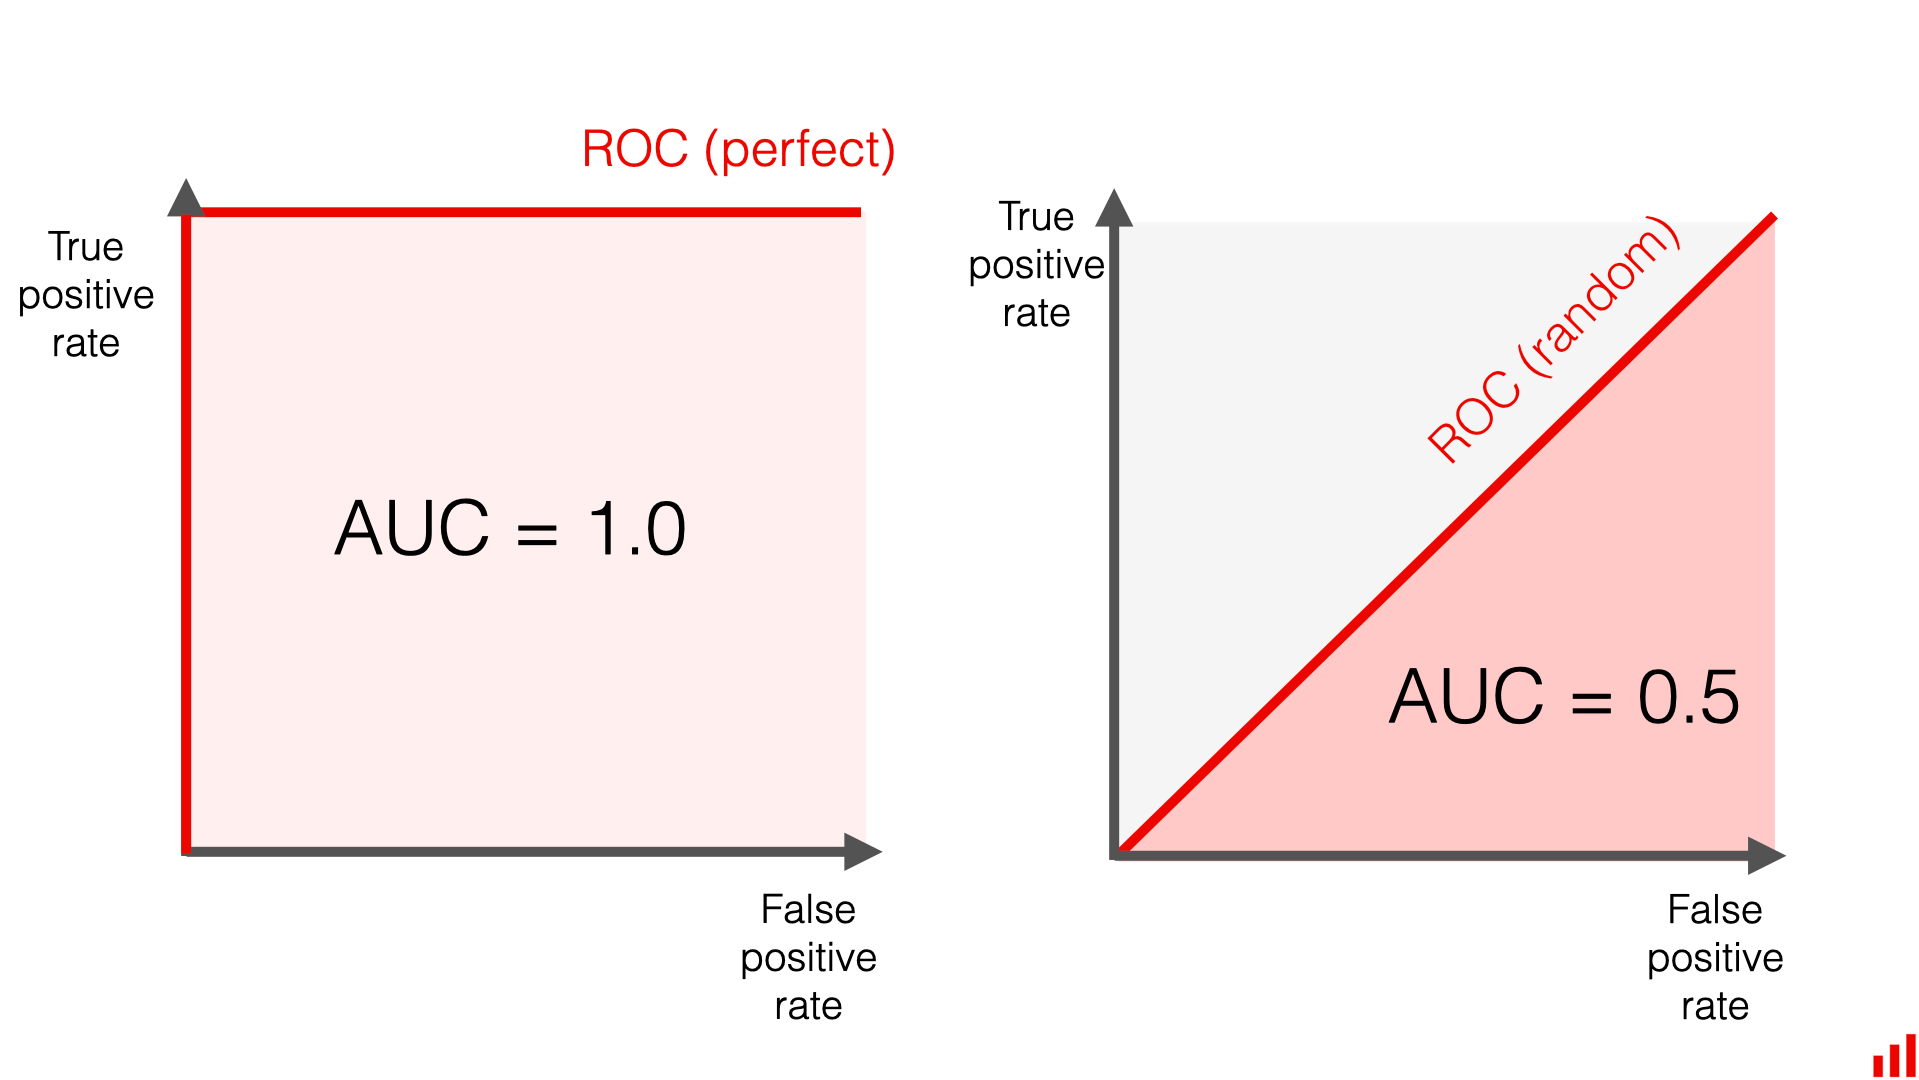

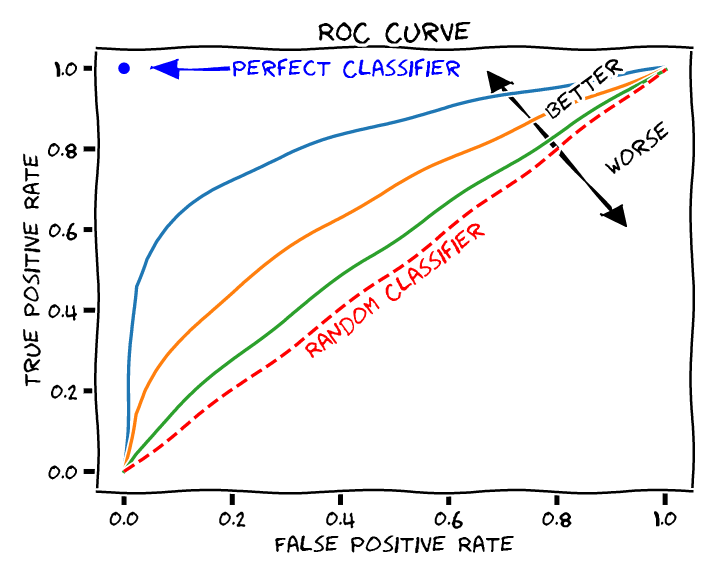

## Step 1: Load and Preprocess Heart Disease Dataset

In [66]:
df = df[[ 'currentSmoker','prevalentStroke', 'age',  'BPMeds', 'prevalentHyp', 'diabetes', 'totChol', 'sysBP', 'diaBP', 'Heart Disease (in next 10 years)']].dropna()

X = df.drop('Heart Disease (in next 10 years)', axis=1)
y = df['Heart Disease (in next 10 years)']
df.tail()

,currentSmoker,prevalentStroke,age,BPMeds,prevalentHyp,diabetes,totChol,sysBP,diaBP,Heart Disease (in next 10 years)
4234,1,0,51,0.0,0,0,207.0,126.5,80.0,0
4236,1,0,44,0.0,0,0,210.0,126.5,87.0,0
4237,0,0,52,0.0,0,0,269.0,133.5,83.0,0
4238,0,0,40,0.0,1,0,185.0,141.0,98.0,0
4239,1,0,39,0.0,0,0,196.0,133.0,86.0,0


## Step 2: Train-Test Split + Scaling

In [59]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


## Step 3: Train Model


In [62]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

# Define models
models = {"Random Forest": RandomForestClassifier()}


## Step 4: Compute ROC & AUC and Plot

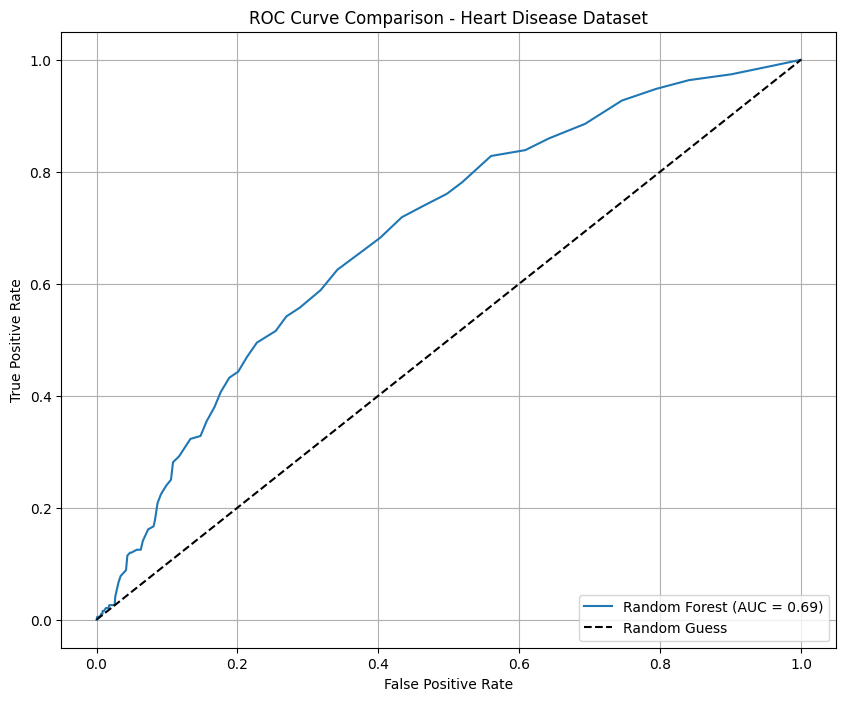

In [63]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

for name, model in models.items():
    # Fit
    model.fit(X_train_scaled, y_train)

    # Predict probabilities for class 1 (survived)
    y_probs = model.predict_proba(X_test_scaled)[:, 1]

    # ROC and AUC
    fpr, tpr, _ = roc_curve(y_test, y_probs)
    roc_auc = auc(fpr, tpr)

    # Plot
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.2f})")

# Plot random line
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')

# Final plot setup
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison - Heart Disease Dataset")
plt.legend(loc="lower right")
plt.grid()
plt.show()


In [64]:
from sklearn.metrics import precision_score, recall_score, f1_score

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    print(f"{name}:")
    print(f"  Precision: {precision:.2f}")
    print(f"  Recall:    {recall:.2f}")
    print(f"  F1-score:  {f1:.2f}")
    print("-" * 30)


Random Forest:
  Precision: 0.22
  Recall:    0.04
  F1-score:  0.06
------------------------------
